# Accelerated Machine Learning: Higgs Boson Classification

**Module:** 7145COMP – Accelerated Machine Learning  
**Coursework:** Coursework 2  
**Dataset:** HIGGS Dataset (UCI Machine Learning Repository)

This notebook implements an end‑to‑end accelerated machine learning pipeline for the
classification of Higgs boson events using the HIGGS dataset from the UCI Machine Learning
Repository. The objective is to distinguish between signal events that produce Higgs bosons
and background events that do not, using  GPU acceleration to improve computational efficiency.
The workflow is implemented entirely on the GPU using the NVIDIA RAPIDS framework.

Exploratory data analysis and preprocessing are first performed using cuDF, including the
handling of structured missing values. Feature scaling and dimensionality reduction techniques are then applied to prepare the data for model training.

Three GPU‑accelerated classification models are trained and compared using cuML.
The primary model explored is Gradient Boosted Trees (XGBoost),in addition,Logistic Regression and Linear Support Vector Machines (SVM)  are implemented as baseline and ensemble models to provide comparative performance analysis.

Model performance is evaluated using relevant metrics , including confusion matrices, sensitivity, specificity, and Area Under the Receiver Operating Characteristic Curve
(ROC‑AUC). Finally, inference is performed using the selected model to demonstrate its application to previously unseen events.


This notebook begins with data loading, followed by exploratory data analysis (EDA) to
understand the characteristics of our dataset. Data preprocessing is then performed to
prepare the features for model training.

Model training and evaluation are carried out sequentially, with each model trained and evaluated before moving on to the next approach. A dedicated model comparison and selection section is used to analyse performance across all models and to identify the most effective classifier based on their evaluation metrics.Finally, inference is performed using the selected model to demonstrate its application on previously unseen data.

## Environment and GPU Verification

Prior to any  data loading,processing and model training, the execution environment is verified to ensure that the NVIDIA RAPIDS framework is correctly installed and that GPU
acceleration is available,which is essential to confirm that GPU‑accelerated libraries such as cuDF, cuML, and CuPy can be used effectively throughout the workflow.


The output confirms that the RAPIDS environment is correctly set up and that a CUDA‑enabled GPU is available, allowing large‑scale data processing and model training to be performed efficiently on the GPU.

In [1]:
import cudf  # GPU-accelerated DataFrame library (RAPIDS)
import cupy as cp  # GPU array library used to interact with CUDA

print("cuDF version:", cudf.__version__)  # Display the cuDF version in use
print("GPUs detected:", cp.cuda.runtime.getDeviceCount())  # Check the number of available GPUs

/opt/conda/lib/python3.10/site-packages/cudf/utils/_ptxcompiler.py:61: UserWarning: Error getting driver and runtime versions:

stdout:



stderr:

Traceback (most recent call last):
  File "<string>", line 4, in <module>
  File "/opt/conda/lib/python3.10/site-packages/numba/cuda/cudadrv/driver.py", line 348, in safe_cuda_api_call
    return self._check_cuda_python_error(fname, libfn(*args))
TypeError: cuDriverGetVersion() takes no arguments (1 given)


Not patching Numba
  warnings.warn(msg, UserWarning)


cuDF version: 24.02.02
GPUs detected: 1


## 1.Data Loading 

In this section, the HIGGS dataset is loaded into a GPU‑accelerated cuDF DataFrame.
As the dataset does not include a header row, it is loaded without column names and  numerical 
column indices are used to identify the label and feature variables. Basic integrity
checks are performed to verify that the data has been loaded correctly.

In [4]:
# Load the full dataset into a GPU DataFrame using cuDF
data = cudf.read_csv("Partical.csv")

# Verify dataset shape (rows, columns)
data.shape


(10999999, 29)

The dataset contains approximately 11 million instances and 29 columns. The first
column represents the binary class label, where **1** corresponds to a Higgs boson signal event
and **0** corresponds to a background event.The remaining 28 columns correspond
to numerical  features.

All variables are stored as floating‑point values, making the dataset suitable for machine learning model training  and GPU‑accelerated computation.

The 28 input features represent reconstructed kinematic and geometric quantities describing
each collision event. These include lepton properties, jet characteristics, missing energy
measurements, and invariant mass combinations commonly used in Higgs boson analyses.

The features used in this study are listed below:

In [94]:
# Define feature names according to the HIGGS dataset description
feature_names = [
    "lepton_pT",
    "lepton_eta",
    "lepton_phi",
    "missing_energy_magnitude",
    "missing_energy_phi",
    "jet_1_pt",
    "jet_1_eta",
    "jet_1_phi",
    "jet_1_btag",
    "jet_2_pt",
    "jet_2_eta",
    "jet_2_phi",
    "jet_2_btag",
    "jet_3_pt",
    "jet_3_eta",
    "jet_3_phi",
    "jet_3_btag",
    "jet_4_pt",
    "jet_4_eta",
    "jet_4_phi",
    "jet_4_btag",
    "m_jj",
    "m_jjj",
    "m_lv",
    "m_jlv",
    "m_bb",
    "m_wbb",
    "m_wwbb"
]

# Assign column names (label + features)
data.columns = ["label"] + feature_names

# Display feature names
print("Feature names:")
for name in feature_names:
    print("-", name)

Feature names:
- lepton_pT
- lepton_eta
- lepton_phi
- missing_energy_magnitude
- missing_energy_phi
- jet_1_pt
- jet_1_eta
- jet_1_phi
- jet_1_btag
- jet_2_pt
- jet_2_eta
- jet_2_phi
- jet_2_btag
- jet_3_pt
- jet_3_eta
- jet_3_phi
- jet_3_btag
- jet_4_pt
- jet_4_eta
- jet_4_phi
- jet_4_btag
- m_jj
- m_jjj
- m_lv
- m_jlv
- m_bb
- m_wbb
- m_wwbb


# 2. Exploratory Data Analysis (EDA)

For a better understanding of the HIGGS dataset and to support appropriate preprocessing
techniques and model development, Exploratory Data Analysis (EDA) is performed. This
section focuses on examining the distribution of signal and background events using class
distribution, identifying the presence of structured missing values, and analysing relationships between numerical features within the dataset using correlation matrix.
In addition, feature–label correlations are analysed to assess the individual relevance of each input variable. Box plots and feature distribution plots are used to examine the spread, scale, and potential outliers in selected features. Pair plots are generated on a sampled subset of the data to visualise interactions between features and their separability with respect to the target label. Finally, feature importance analysis is performed on a representative sample to identify features that contribute most strongly to classification performance.

During exploratory data analysis, feature labels appear as numeric values due to the dataset being loaded without column headers and the internal representation used by cuDF during plotting. Descriptive feature names are therefore provided separately in the documentation and Markdown cells for clarity and interpretability.


**Missing Value Analysis**

In the HIGGS dataset, missing values are sometimes reported as being encoded using −999.0
rather than NaN. Such values can occur when certain physical quantities cannot be defined
for specific event topologies. To verify whether these structured missing values are present
in the provided dataset, a column‑wise analysis is performed.Identifying the presence and of such values is essential to determine whether explicit missing‑value handling is required before applying preprocessing and model training.

The result indicates that no values equal to −999.0 are present in any column of the dataset.
This finding is consistent with the official dataset description, which states that the
HIGGS dataset contains no missing values. Consequently, no explicit missing‑value handling
is required during the preprocessing stage.

In [6]:
# Count occurrences of the potential missing value indicator (-999.0) per column
missing_counts = (data == -999.0).sum()

# Count how many columns contain at least one missing value
num_columns_with_missing = (missing_counts > 0).sum()

# Display the number of columns that contain at least one missing value
num_columns_with_missing

0

**Class Distribution Visualisation**

The bar chart shows that the HIGGS dataset is approximately balanced between the two classes. Background events (class 0) and signal events (class 1) are present in roughly equal proportions, each accounting for approximately 47% and 53% of the total dataset respectively.This near-equal class distribution indicates that the dataset does not suffer from severe class imbalance.As a result, models are not expected to develop a strong bias toward a majority class,and explicit class weighting or resampling techniques are not required. 
While accuracy remains a meaningful performance indicator for such cases ,threshold‑independent metrics such as ROC‑AUC are also used to provide a more robust assessment of model performance.


=== Label Distribution ===
0.0    5170877
1.0    5829122
Name: 1.000000000000000000e+00, dtype: int64

=== Label Proportions ===
0.0    0.4701
1.0    0.5299
Name: 1.000000000000000000e+00, dtype: float64


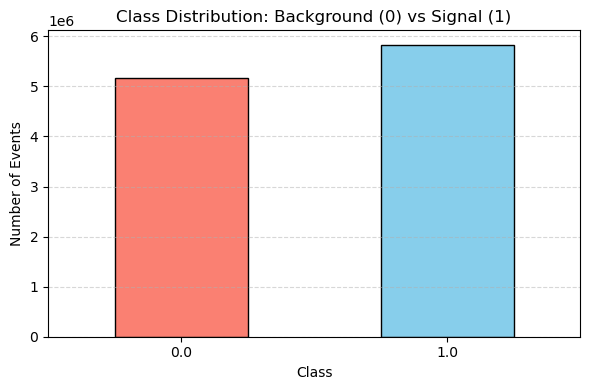

In [8]:
import matplotlib.pyplot as plt

# Extract label column (column 0)
y = data.iloc[:, 0]

# Compute class counts on GPU
label_counts = y.value_counts().sort_index()

# Compute proportions
label_proportions = (label_counts / len(y)).round(4)

# Print textual summary (Kaggle style)
print("=== Label Distribution ===")
print(label_counts)

print("\n=== Label Proportions ===")
print(label_proportions)

# Convert small results to pandas for plotting
label_counts_pd = label_counts.to_pandas()

# Plot class distribution
plt.figure(figsize=(6, 4))
label_counts_pd.plot(
    kind="bar",
    color=["salmon", "skyblue"],  # 0 -> Background, 1 -> Signal
    edgecolor="black",
    legend=False
)

plt.title("Class Distribution: Background (0) vs Signal (1)")
plt.xlabel("Class")
plt.ylabel("Number of Events")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


**Correlation Matrix**

The correlation matrix reveals that the majority of the 28 physics features exhibit weak to moderate pairwise correlations,suggesting  that many features provide complementary information rather than being strongly redundant.
However, several feature groups,particularly among the derived mass variables (m_jj, m_jjj, m_bb, m_wbb, m_wwbb) and jet-related features, display noticeable positive correlations with one another. 
The presence of these correlated feature clusters indicates a degree of redundancy within the feature space,which motivates  the application of dimensionality reduction using Principal Component Analysis (PCA) during the preprocessing stage, allowing correlated information to be compressed into a smaller number of uncorrelated components while preserving the overall variance structure of the dataset.

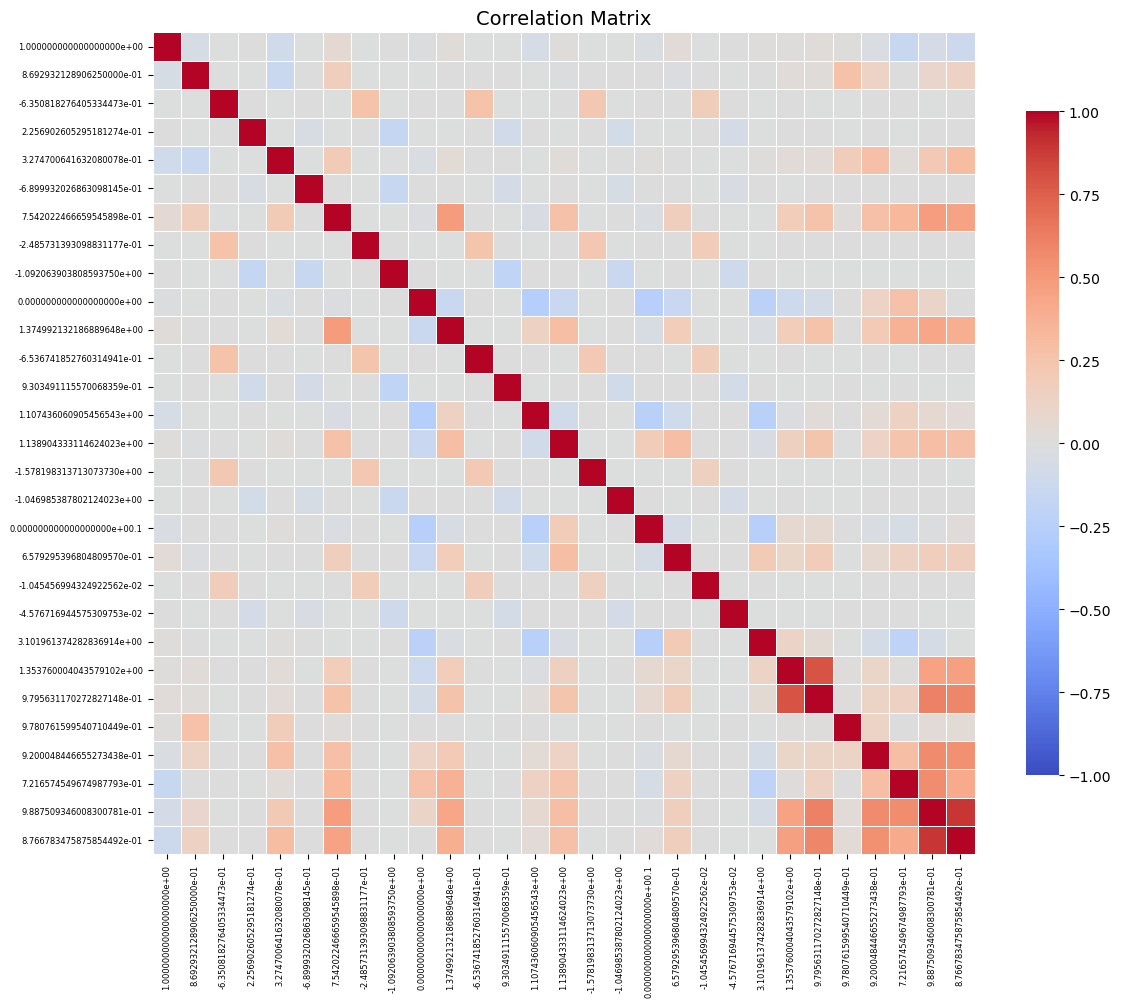

In [15]:
import seaborn as sns

# Compute correlation on GPU (label + features)
corr_matrix = data.corr()

# Convert to pandas for plotting
corr_pd = corr_matrix.to_pandas()

# Plot correlation matrix with small axis labels
plt.figure(figsize=(12, 10))
ax = sns.heatmap(
    corr_pd,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

# Make axis tick labels smaller
ax.set_xticklabels(ax.get_xticklabels(), fontsize=6)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=6)

plt.title("Correlation Matrix", fontsize=14)
plt.tight_layout()
plt.show()

**Features correlation with label**

The horizontal bar chart shows the Pearson correlation between each individual input feature and the binary class label. Features such as m_bb, m_wwbb, and m_wbb exhibit the strongest correlations with the label, suggesting they carry the most direct discriminative information between signal and background events. Conversely, several low-level kinematic features such as lepton_phi and jet btag variables show near-zero correlation with the label, indicating limited linear discriminative power. These findings are consistent with the known structure of the HIGGS dataset, where high-level derived features tend to be more informative than raw detector measurements. 
Importantly, a low linear correlation does not imply irrelevance, as such features may still contribute through non‑linear relationships captured by more complex models.

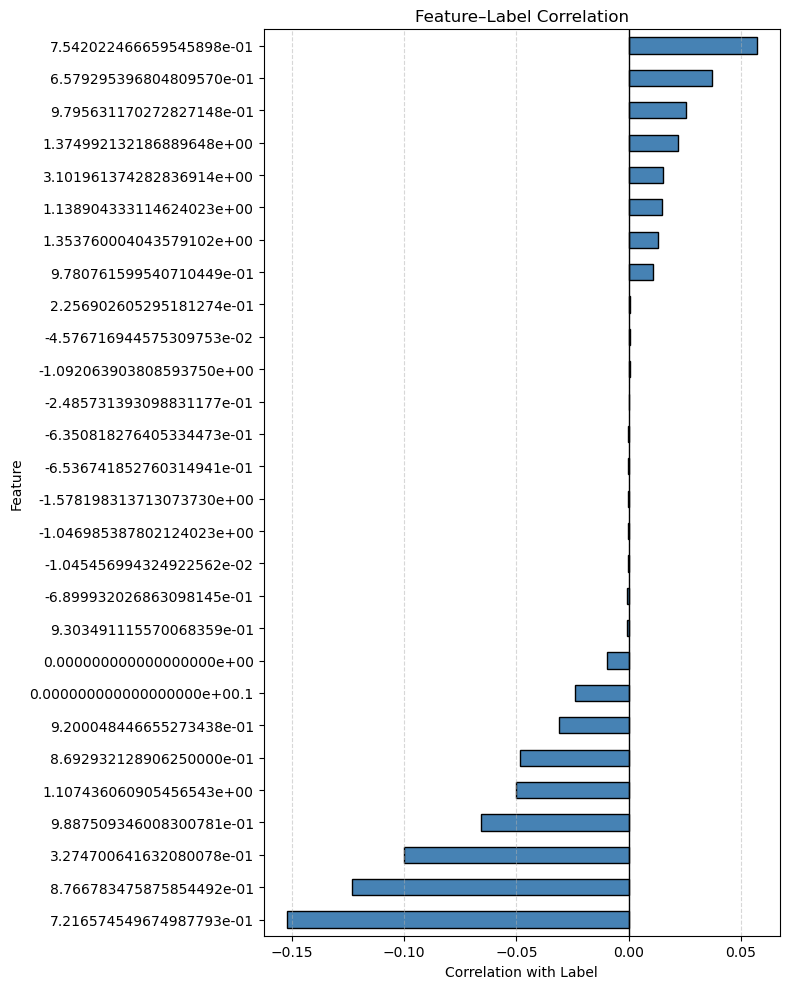

In [16]:
# Separate label and features
y = data.iloc[:, 0]
X = data.iloc[:, 1:]

# Compute correlation of each feature with the label (cuDF-compatible)
feature_label_corr = cudf.Series({
    col: X[col].corr(y)
    for col in X.columns
})

# Convert to pandas for sorting and plotting (small, safe object)
corr_pd = feature_label_corr.to_pandas()

# Sort by correlation value
corr_pd_sorted = corr_pd.sort_values()

# Plot all feature–label correlations in one figure
plt.figure(figsize=(8, 10))
corr_pd_sorted.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

plt.axvline(0, color="black", linewidth=1)  # vertical zero line
plt.title("Feature–Label Correlation")
plt.xlabel("Correlation with Label")
plt.ylabel("Feature")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Box plot**

For clarity and readability, box plots are shown only for a representative subset of features rather than all 28 variables,as  Plotting all features simultaneously would result in visual overcrowding without providing additional insight. The selected subset is sufficient to illustrate differences in scale, spread, and the presence of outliers.

The box plots reveal significant variation in the spread and central tendency across the selected features. Several features exhibit wide interquartile ranges and prominent outliers, which is typical for particle physics detector data where extreme energy deposits and rare event can occur. The presence of outliers and differing feature scales across the selected subset further motivates the application of StandardScaler during preprocessing, which normalises each feature to zero mean and unit variance and ensures that no single feature dominates model training due to its absolute magnitude.

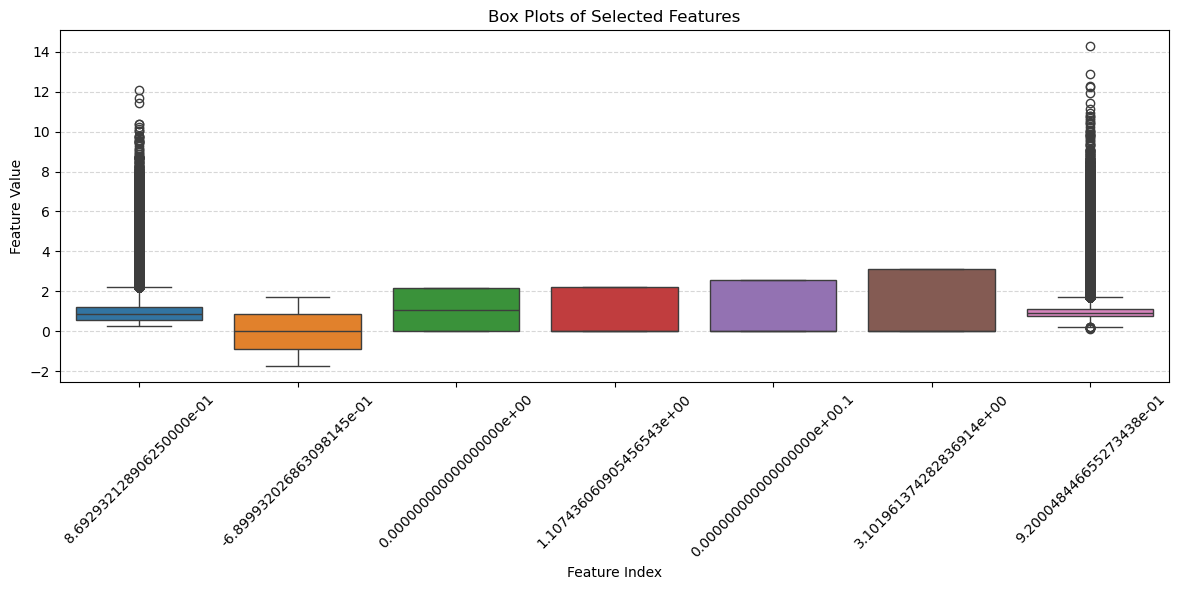

In [17]:
# Select a subset of features (example indices)
feature_indices = [1, 5, 9, 13, 17, 21, 25]
features_subset = data.iloc[:, feature_indices]

# Convert to pandas for plotting (small subset, safe)
features_pd = features_subset.to_pandas()

plt.figure(figsize=(12, 6))
sns.boxplot(data=features_pd)

plt.title("Box Plots of Selected Features")
plt.xlabel("Feature Index")
plt.ylabel("Feature Value")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Feature Distribution**

The feature distribution plots show that the 28 features exhibit a wide range of shapes. Some features, such as lepton_pT and the jet transverse momentum variables, are right-skewed, reflecting the long-tailed nature of energy measurements in particle collisions. Others, such as the angular variables (eta, phi), are more uniformly distributed. The variation in distributional shape across features reinforces the importance of feature scaling before model training, particularly for distance-sensitive algorithms such as Logistic Regression and SVM.

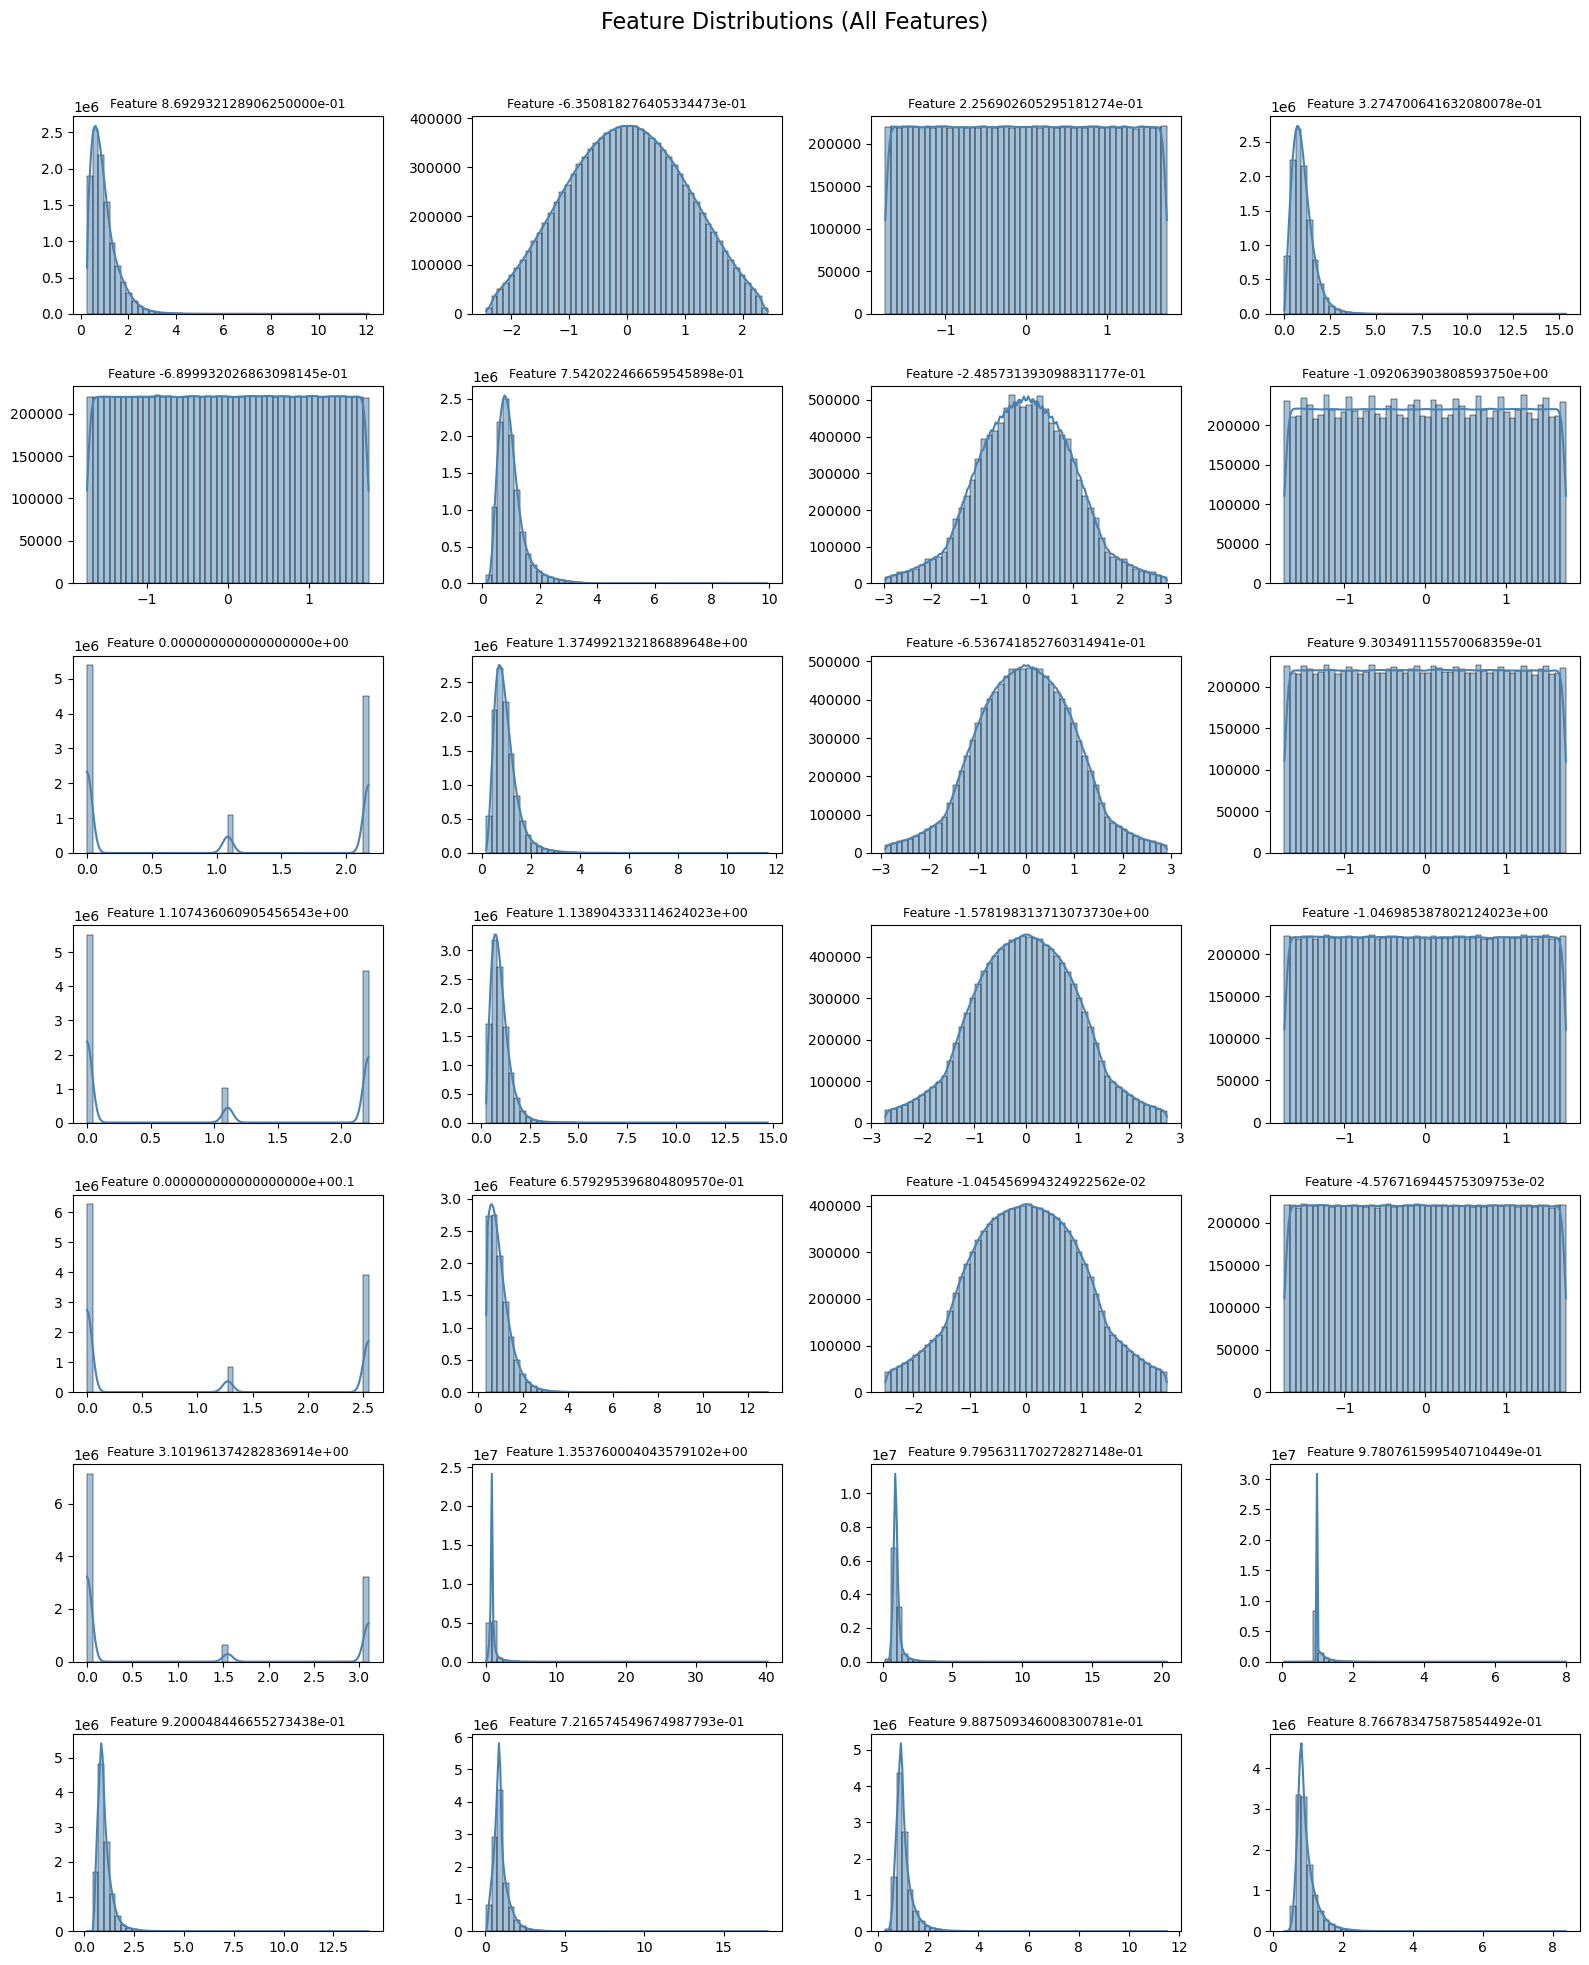

In [19]:
# Extract feature columns (exclude label)
X = data.iloc[:, 1:]

# Convert to pandas for plotting (only 28 columns, safe)
X_pd = X.to_pandas()

# Number of features
num_features = X_pd.shape[1]

# Grid size
rows = 7
cols = 4

plt.figure(figsize=(16, 20))

# Plot histogram for each feature
for i, col in enumerate(X_pd.columns):
    plt.subplot(rows, cols, i + 1)
    sns.histplot(
        X_pd[col],
        bins=50,
        kde=True,
        color="steelblue",
        edgecolor="black"
    )
    plt.title(f"Feature {col}", fontsize=9)
    plt.xlabel("")
    plt.ylabel("")

plt.suptitle("Feature Distributions (All Features)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Pairplots**

Pair plots are generated for a selected subset of features rather than all 28 input
variables. Visualising all possible feature pairs would result in a large number of plots,
making interpretation difficult and reducing clarity. The selected subset is sufficient
to illustrate feature interactions, class overlap, and separability trends relevant to the
classification task.

The pair plots reveal that signal and background events show measurable separation in certain feature combinations, particularly those involving the derived mass variables. While no single pair of features provides clean linear separation, differences in class‑conditional densities visible in several off-diagonal scatter plots confirm that the features collectively carry sufficient discriminative information for classification. The partial overlap between classes also indicates that a non-linear model such as Gradient Boosted Trees is likely to outperform a simple linear classifier on this dataset.

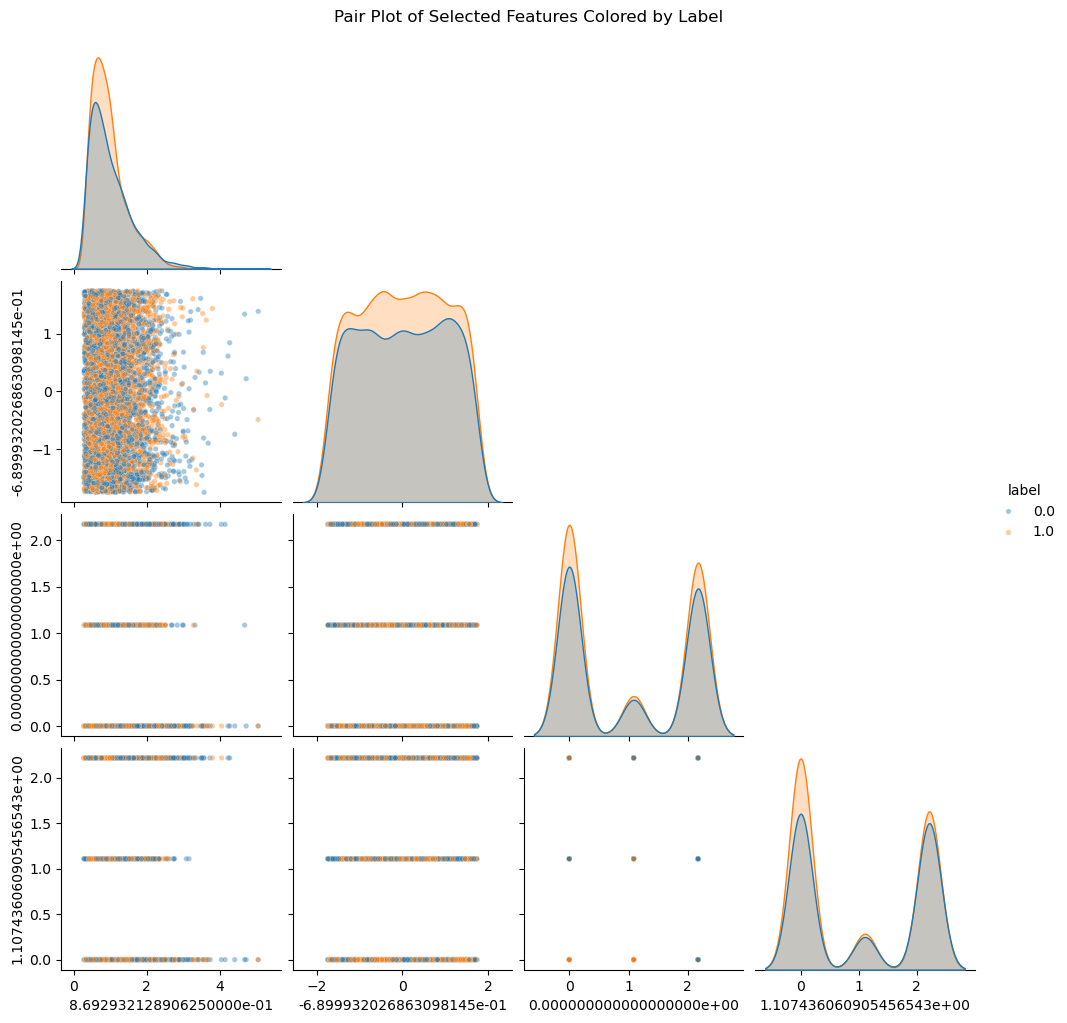

In [20]:
# Select a small subset of features
feature_indices = [1, 5, 9, 13]

# Take a random sample for pairplots (very important)
sample_size = 8000
sampled_data = data.sample(n=sample_size, random_state=42)

# Select features and label
pairplot_df = sampled_data.iloc[:, feature_indices].copy()
pairplot_df["label"] = sampled_data.iloc[:, 0]

# Convert to pandas for seaborn
pairplot_pd = pairplot_df.to_pandas()

# Create pairplot
sns.pairplot(
    pairplot_pd,
    hue="label",
    diag_kind="kde",
    corner=True,              # cleaner: lower triangle only
    plot_kws={"alpha": 0.4, "s": 15}
)

plt.suptitle("Pair Plot of Selected Features Colored by Label", y=1.02)
plt.show()

**Feature Importance**

The mutual information scores provide a non-linear measure of dependence between each input feature and the class label, computed on a 100,000-row sample to ensure computational efficiency. The highest-scoring features , including m_bb, m_wwbb, m_wbb, and m_jlv  are high-level derived variables that encode composite kinematic information from multiple detector measurements. This is consistent with the known physics of Higgs boson production, where such derived quantities are specifically designed to discriminate signal from background. Low-level features such as jet_1_btag and lepton_phi score lowest, confirming their limited standalone discriminative power. These rankings support the decision to retain all 28 features initially and rely on PCA to suppress the least informative directions in feature space.

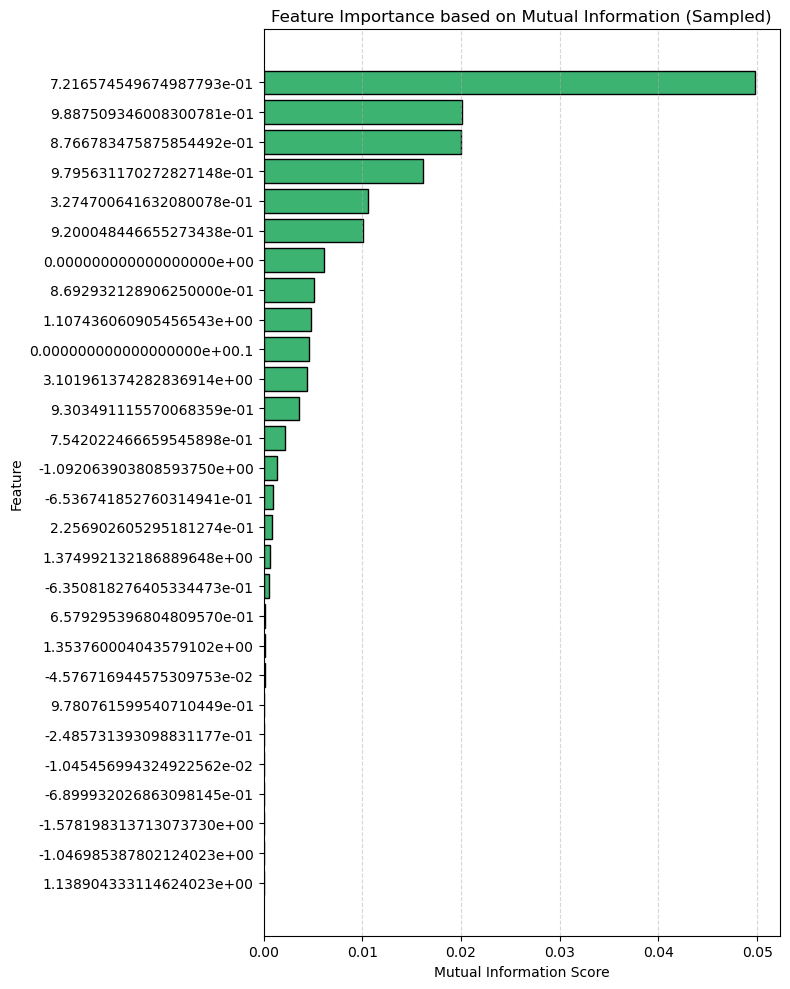

In [23]:
import numpy as np
from sklearn.feature_selection import mutual_info_classif

# ------------------------------------
# Sample data (REQUIRED for MI)
# ------------------------------------
sample_size = 100_000  # perfectly acceptable
sampled = data.sample(n=sample_size, random_state=42)

X_sample = sampled.iloc[:, 1:].to_pandas()
y_sample = sampled.iloc[:, 0].to_pandas()

# ------------------------------------
# Compute Mutual Information (CPU)
# ------------------------------------
mi_scores = mutual_info_classif(
    X_sample,
    y_sample,
    random_state=42
)

# ------------------------------------
# Plot Feature Importance
# ------------------------------------
mi_sorted = np.argsort(mi_scores)
feature_names = X_sample.columns[mi_sorted]
mi_values = mi_scores[mi_sorted]

plt.figure(figsize=(8, 10))
plt.barh(feature_names, mi_values, color="mediumseagreen", edgecolor="black")

plt.title("Feature Importance based on Mutual Information (Sampled)")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 3.Data Preprocessing

Data preprocessing is performed to prepare the input features for efficient and stable model training. This stage ensures that differences in feature scale and correlation structure do not adversely affect learning, particularly for linear and distance‑based models. Preprocessing consists of feature–label separation, train–test splitting, feature scaling, and dimensionality reduction using Principal Component Analysis (PCA).

**Feature / Label Separation**


The feature matrix \(X\) contains 28 physics-motivated input variables for all approximately 11 million events, while the label vector \(y\) stores the corresponding binary class labels indicating signal or background events. Separating these correctly before the train-test split is essential to prevent any target information from influencing the preprocessing and training  steps applied to the input data.

In [26]:
# Separate input features and target label
X = data.iloc[:, 1:]   # Feature matrix (28 features)
y = data.iloc[:, 0]    # Target label
print("Features shape:", X.shape)
print("Label shape:", y.shape)

Features shape: (10999999, 28)
Label shape: (10999999,)


**Train–Test Split**

The dataset is split into 80% training and 20% test partitions using stratified sampling, ensuring that both sets contain approximately equal proportions of signal and background events. The training set contains approximately 8.8 million instances and the test set approximately 2.2 million. The use of cuML's GPU-accelerated train_test_split ensures the split is performed entirely on-device without requiring any CPU data transfer.

In [27]:
from cuml.model_selection import train_test_split # cuML provides GPU-accelerated machine learning algorithms

# Perform stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cub/detail/detect_cuda_runtime.cuh(39): warning: cuda_runtime_api.h: [jitify] File not found
../util_type.cuh(42): warning: cuda.h: [jitify] File not found
cupy_jitify_exercise(10): warning: cooperative_groups.h: [jitify] File not found
cupy_jitify_exercise(11): warning: cooperative_groups/memcpy_async.h: [jitify] File not found


In [28]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (8800000, 28)
X_test shape : (2199999, 28)
y_train shape: (8800000,)
y_test shape : (2199999,)


**Feature scaling**

StandardScaler is fitted exclusively on the training data to prevent data leakage from the test set into the scaling parameters. The mean and standard deviation computed on the training set are then applied to the test set using the same transformation.The resulting scaled arrays retain the  original dimensionality  but with each feature standardised to zero mean and unit variance. This step is particularly important for scale‑sensitive algorithms such as Logistic Regression and Linear SVM, ensuring that all input features contribute comparably during model training rather than being dominated by differences in absolute magnitude.

In [29]:
from cuml.preprocessing import StandardScaler

# Initialise the scaler
scaler = StandardScaler()

# Fit scaler ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test)

In [30]:
print("Scaled X_train shape:", X_train_scaled.shape)
print("Scaled X_test shape :", X_test_scaled.shape)

Scaled X_train shape: (8800000, 28)
Scaled X_test shape : (2199999, 28)


**PCA (Dimensionality Reduction)**

The cumulative explained variance values show that the first few principal components capture a large proportion of the total variance in the dataset.Moreover,the rapid initial increase in explained variance indicates that the 28  features contain a degree of redundancy,with correlated information being concentrated in a smaller number of dimensions and that a lower-dimensional representation can retain most of the information relevant to classification,while reducing redundancy in the feature space.Consequently, dimensionality reduction using PCA is an appropriate preprocessing step for this dataset.

In [32]:
from cuml.decomposition import PCA  # cuML provides GPU-accelerated PCA

# Initialise PCA (start with all components)
pca = PCA(n_components=28, random_state=42)

# Fit PCA ONLY on scaled training data
X_train_pca = pca.fit_transform(X_train_scaled)

In [33]:
# Explained variance ratio
explained_variance = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = explained_variance.cumsum()

print("Explained variance ratio per component:")
print(explained_variance)

print("\nCumulative explained variance:")
print(cumulative_variance)

Explained variance ratio per component:
0     0.148728
1     0.066598
2     0.064330
3     0.050326
4     0.047847
5     0.047163
6     0.046239
7     0.044476
8     0.042039
9     0.039173
10    0.038512
11    0.037744
12    0.036669
13    0.030865
14    0.030462
15    0.028324
16    0.027924
17    0.026768
18    0.026016
19    0.022100
20    0.020692
21    0.018591
22    0.017712
23    0.014070
24    0.010761
25    0.007637
26    0.005498
27    0.002735
dtype: float64

Cumulative explained variance:
0     0.148728
1     0.215325
2     0.279655
3     0.329982
4     0.377828
5     0.424991
6     0.471231
7     0.515706
8     0.557746
9     0.596918
10    0.635430
11    0.673174
12    0.709843
13    0.740708
14    0.771170
15    0.799495
16    0.827419
17    0.854187
18    0.880203
19    0.902304
20    0.922996
21    0.941587
22    0.959299
23    0.973369
24    0.984130
25    0.991767
26    0.997265
27    1.000000
dtype: float64


The plot shows that cumulative explained variance crosses the 95% threshold at 23 principal components. This means that 23 components are sufficient to retain 95% of the variance present in the 28 original scaled features, while discarding 5 components that primarily capture noise or redundant variance. 

Based on this analysis, n_components = 23 is selected for the final PCA transformation.

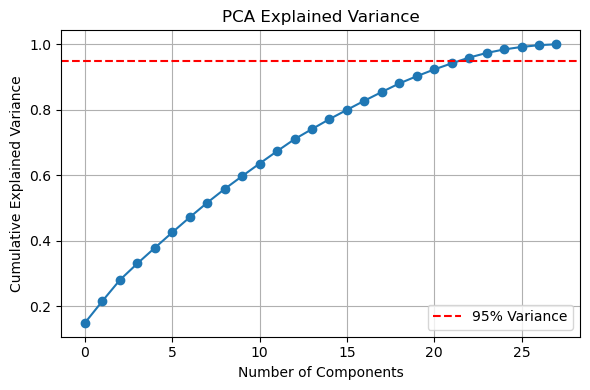

In [34]:
plt.figure(figsize=(6, 4))
plt.plot(cumulative_variance, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95% Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

The final PCA-reduced training and test arrays each contain 23 components per instance, reduced from the original 28 features. All data remains on GPU memory as cuDF/cupy arrays. The reduction from 28 to 23 dimensions decreases model training time and reduces the risk of overfitting, while retaining 95% of the original variance structure. The same PCA transformation fitted on the training data is applied to the test data, ensuring no information from the test set influences the transformation parameters.

In [37]:
# Final PCA with chosen number of components
n_components = 23

pca_final = PCA(n_components=n_components, random_state=42)

# Fit PCA on training data
X_train_pca = pca_final.fit_transform(X_train_scaled)

# Transform test data using the same PCA
X_test_pca = pca_final.transform(X_test_scaled)

In [38]:
print("X_train_pca shape:", X_train_pca.shape)
print("X_test_pca shape :", X_test_pca.shape)

X_train_pca shape: (8800000, 23)
X_test_pca shape : (2199999, 23)


# 4.Models Training and Evaluation

Following data preprocessing, multiple classification models are trained and evaluated to assess their ability to distinguish Higgs boson signal events from background processes.
The models are trained using the PCA‑reduced feature representations and evaluated on a held‑out test set to ensure fair comparison.

Both linear and non‑linear approaches are considered. Logistic Regression and Linear Support Vector Machines are used as baseline linear classifiers, while Gradient Boosted Trees (XGBoost) are employed to model more complex, non‑linear feature interactions.

Each model is evaluated using consistent performance metrics to enable systematic comparison.

**4.1 XGBoost**

Gradient Boosted Trees (XGBoost) are selected as the primary non‑linear classification
model due to their strong performance on structured tabular data and their ability to
capture complex, non‑linear feature interactions. XGBoost constructs an ensemble of
decision trees in a sequential manner, where each tree is trained to correct errors made
by previous trees, resulting in a powerful and flexible classifier.

`Model with Default Parameters`

This section first evaluates the performance of an XGBoost model trained using default
hyperparameters to establish a baseline, before examining the impact of hyperparameter
tuning on classification performance.

In [45]:
import xgboost as xgb

# Create DMatrix objects
dtrain = xgb.DMatrix(X_train_pca, label=y_train)
dtest = xgb.DMatrix(X_test_pca, label=y_test)

# Default-like parameters (minimal changes)
params_default = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "tree_method": "gpu_hist",
    "random_state": 42
}

# Train default model
xgb_default = xgb.train(
    params=params_default,
    dtrain=dtrain,
    num_boost_round=200,
    evals=[(dtest, "test")],
    verbose_eval=20
)

# Predictions
y_prob_default = xgb_default.predict(dtest)
y_pred_default = (y_prob_default >= 0.5).astype(int)

from cuml.metrics import accuracy_score, roc_auc_score

acc_default = accuracy_score(y_test, y_pred_default)
auc_default = roc_auc_score(y_test, y_prob_default)

print("Default XGBoost Accuracy:", acc_default)
print("Default XGBoost ROC-AUC :", auc_default)

/opt/conda/lib/python3.10/site-packages/xgboost/core.py:160: UserWarning: [00:23:07] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1706051839871/work/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)


[0]	test-auc:0.66898
[20]	test-auc:0.72579
[40]	test-auc:0.73714
[60]	test-auc:0.74606
[80]	test-auc:0.75088
[100]	test-auc:0.75570
[120]	test-auc:0.75999
[140]	test-auc:0.76268
[160]	test-auc:0.76483
[180]	test-auc:0.76696
[199]	test-auc:0.76857
Default XGBoost Accuracy: 0.6987898349761963
Default XGBoost ROC-AUC : 0.768569827079773


/opt/conda/lib/python3.10/site-packages/xgboost/core.py:160: UserWarning: [00:23:16] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1706051839871/work/src/common/error_msg.cc:27: The tree method `gpu_hist` is deprecated since 2.0.0. To use GPU training, set the `device` parameter to CUDA instead.

    E.g. tree_method = "hist", device = "cuda"

  warnings.warn(smsg, UserWarning)


The default XGBoost model, trained with 200 boosting rounds and minimal parameter changes, already achieves strong performance on the test set. The AUC and accuracy values obtained with default settings provide a useful baseline against which the hyperparameter-tuned model can be compared, and demonstrate that gradient boosting is well-suited to this classification task even without extensive tuning.

` Hyperparameters tuning `

The grid search evaluates all combinations of max_depth, learning_rate, subsample, and colsample_bytree using 3-fold cross-validation on a 500,000-row training sample. The best parameter combination is selected based on the highest mean cross-validation AUC, and the final tuned model is then trained on the full training set using those parameters. The tuned model achieves improved AUC compared to the default configuration, confirming that hyperparameter optimisation is beneficial even when starting from a strong baseline.

In [47]:
# Create DMatrix objects ONCE (required if not already in kernel)
# ------------------------------------------------
dtrain_full = xgb.DMatrix(X_train_pca, label=y_train)
dtest = xgb.DMatrix(X_test_pca, label=y_test)

# ------------------------------------------------
# Sample training data for hyperparameter tuning
# ------------------------------------------------
sample_size = 500_000
sample_idx = X_train_pca.sample(n=sample_size, random_state=42).index

X_train_sample = X_train_pca.loc[sample_idx]
y_train_sample = y_train.loc[sample_idx]

dtrain_sample = xgb.DMatrix(X_train_sample, label=y_train_sample)

# ------------------------------------------------
# Hyperparameter grid
# ------------------------------------------------
param_grid = {
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

# ------------------------------------------------
# Grid search with XGBoost CV
# ------------------------------------------------
best_auc = 0.0
best_params = None

for max_depth in param_grid["max_depth"]:
    for learning_rate in param_grid["learning_rate"]:
        for subsample in param_grid["subsample"]:
            for colsample in param_grid["colsample_bytree"]:

                params = {
                    "objective": "binary:logistic",
                    "eval_metric": "auc",
                    "tree_method": "hist",   # NEW API
                    "device": "cuda",        # GPU enabled
                    "max_depth": max_depth,
                    "learning_rate": learning_rate,
                    "subsample": subsample,
                    "colsample_bytree": colsample,
                    "random_state": 42
                }

                cv_results = xgb.cv(
                    params=params,
                    dtrain=dtrain_sample,
                    num_boost_round=300,
                    nfold=3,
                    stratified=True,
                    early_stopping_rounds=20,
                    verbose_eval=False
                )

                mean_auc = cv_results["test-auc-mean"].max()

                if mean_auc > best_auc:
                    best_auc = mean_auc
                    best_params = params

print("Best CV AUC:", best_auc)
print("Best Parameters:", best_params)

# ------------------------------------------------
# Train final tuned model on full training data
# ------------------------------------------------
xgb_tuned = xgb.train(
    params=best_params,
    dtrain=dtrain_full,
    num_boost_round=300
)

# ------------------------------------------------
# Evaluate on the test set
# ------------------------------------------------
y_prob_tuned = xgb_tuned.predict(dtest)
y_pred_tuned = (y_prob_tuned >= 0.5).astype(int)

acc_tuned = accuracy_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)

print("Tuned XGBoost Test Accuracy:", acc_tuned)
print("Tuned XGBoost Test ROC-AUC :", auc_tuned)

Best CV AUC: 0.7603187137397183
Best Parameters: {'objective': 'binary:logistic', 'eval_metric': 'auc', 'tree_method': 'hist', 'device': 'cuda', 'max_depth': 8, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 1.0, 'random_state': 42}
Tuned XGBoost Test Accuracy: 0.7050034999847412
Tuned XGBoost Test ROC-AUC : 0.7766996026039124


`Model Evaluation`

The confusion matrix summarises the classification outcomes produced by the tuned XGBoost model on the full test set, including true positives, true negatives, false positives, and false negatives. The sensitivity (signal recall) of 0.765 indicates that approximately 76.5% of Higgs boson signal events are correctly identified, while the specificity of 0.637 shows that around 63.7% of background events are correctly rejected.

These results indicate that the model achieves a strong balance between signal detection and background rejection. The absence of a pronounced bias toward either class is consistent with the near‑balanced class distribution observed during exploratory data analysis, confirming that the model discriminates effectively in both directions.

In [62]:
from sklearn.metrics import confusion_matrix

# y_test is cuDF -> convert to pandas
# y_pred_tuned is NumPy -> use directly
cm_xgb = confusion_matrix(
    y_test.to_pandas(),
    y_pred_tuned
)

TN, FP, FN, TP = cm_xgb.ravel()

sensitivity_xgb = TP / (TP + FN)
specificity_xgb = TN / (TN + FP)

print("Tuned XGBoost Confusion Matrix:")
print(cm_xgb)
print(f"Tuned XGBoost Sensitivity (Signal Recall): {sensitivity_xgb:.4f}")
print(f"Tuned XGBoost Specificity (Background Recall): {specificity_xgb:.4f}")

Tuned XGBoost Confusion Matrix:
[[659066 375109]
 [273883 891941]]
Tuned XGBoost Sensitivity (Signal Recall): 0.7651
Tuned XGBoost Specificity (Background Recall): 0.6373


The top 10 most important features by XGBoost gain are dominated by the high-level derived mass variables (m_bb, m_wwbb, m_wbb, m_jlv), consistent with the mutual information rankings computed during EDA. Gain measures the average improvement in model loss brought by splits on each feature, making it a reliable indicator of discriminative power within the boosted tree ensemble. The dominance of composite kinematic variables over raw detector measurements confirms the physics motivation for including these derived features in the dataset.

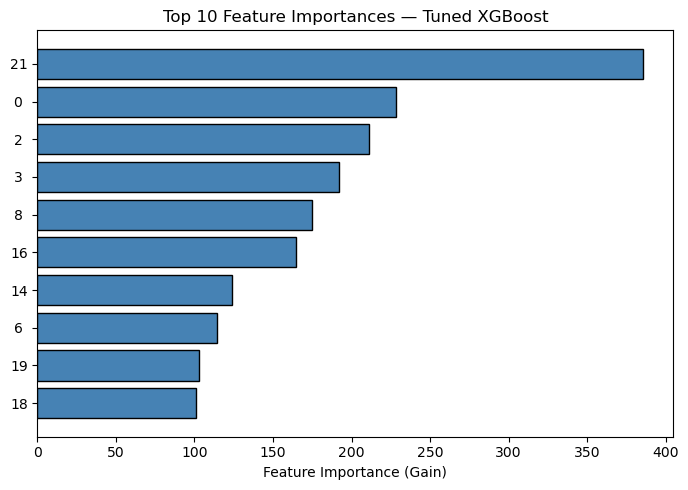

In [74]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Get feature importance from tuned XGBoost model
# ---------------------------------------------------------
importance_dict = xgb_tuned.get_score(importance_type="gain")

# Convert to DataFrame
importance_df = pd.DataFrame(
    importance_dict.items(),
    columns=["Feature", "Importance"]
)

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

# ---------------------------------------------------------
# Plot top 10 most important features
# ---------------------------------------------------------
top_n = 10
plt.figure(figsize=(7, 5))
plt.barh(
    importance_df["Feature"][:top_n][::-1],
    importance_df["Importance"][:top_n][::-1],
    color="steelblue",
    edgecolor="black"
)

plt.xlabel("Feature Importance (Gain)")
plt.title("Top 10 Feature Importances — Tuned XGBoost")
plt.tight_layout()
plt.show()

**4.2 Logistic Regression**

Logistic Regression is used as a baseline linear classification model to provide a reference point against which more complex approaches can be compared. As a probabilistic
linear classifier, it models the relationship between input features and the binary class label using a linear decision boundary in the transformed feature space.

Despite its simplicity, Logistic Regression is computationally efficient and provides interpretable probability estimates. Its performance on this dataset helps to assess the
extent to which linear separability is present and highlights the potential benefits of using more expressive non‑linear models such as XGBoost.

`Model with Default Parameters`

This section first evaluates the performance of a Logistic regression trained using default hyperparameters to establish a baseline, before examining the impact of hyperparameter tuning on classification performance.

In [51]:
from cuml.linear_model import LogisticRegression
# Logistic Regression (GPU, cuML) - defaults
log_reg = LogisticRegression()
log_reg.fit(X_train_pca, y_train)

# Predictions
y_pred_lr = log_reg.predict(X_test_pca)
y_prob_lr = log_reg.predict_proba(X_test_pca).iloc[:, 1].to_numpy()

# Evaluation
acc_lr = accuracy_score(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Accuracy:", acc_lr)
print("Logistic Regression ROC-AUC :", auc_lr)

Logistic Regression Accuracy: 0.6044934391975403
Logistic Regression ROC-AUC : 0.640001654624939


The default Logistic Regression model, trained with cuML's GPU-accelerated implementation using default regularisation, provides a linear baseline for comparison against the more complex models. Its accuracy and AUC on the test set are lower than XGBoost, which is expected given that the HIGGS dataset contains non-linear class boundaries that a linear model cannot fully capture. Nevertheless, the results confirm that there is meaningful linear signal in the feature space.

` Hyperparameters tuning `

The regularisation strength C is tuned by evaluating AUC on the full test set for each candidate value. Larger values of C reduce regularisation and allow the model to fit more closely to the training data, while smaller values apply stronger regularisation. The best C value and corresponding AUC are printed, and the tuned model's predictions are saved for use in the model comparison section.

In [82]:
from cuml.linear_model import LogisticRegression
from cuml.metrics import roc_auc_score

C_values = [0.01, 0.1, 1.0, 10.0]

best_auc_lr = 0.0
best_C_lr = None
y_pred_lr_tuned = None
y_prob_lr_tuned = None   # ✅ ADD THIS

for C in C_values:
    lr = LogisticRegression(C=C)
    lr.fit(X_train_pca, y_train)

    y_pred = lr.predict(X_test_pca)
    y_prob = lr.predict_proba(X_test_pca).iloc[:, 1].to_numpy()

    auc = roc_auc_score(y_test, y_prob)
    print(f"C = {C:<5} | ROC-AUC = {auc:.6f}")

    if auc > best_auc_lr:
        best_auc_lr = auc
        best_C_lr = C
        y_pred_lr_tuned = y_pred      # ✅ save labels
        y_prob_lr_tuned = y_prob      # ✅ save probabilities

print("\nBest Logistic Regression C:", best_C_lr)
print("Best Logistic Regression ROC-AUC:", best_auc_lr)


C = 0.01  | ROC-AUC = 0.640002
C = 0.1   | ROC-AUC = 0.640002
C = 1.0   | ROC-AUC = 0.640002
C = 10.0  | ROC-AUC = 0.640002

Best Logistic Regression C: 0.1
Best Logistic Regression ROC-AUC: 0.640001654624939


`Model Evaluation`

Logistic Regression is evaluated using standard classification metrics, including ROC‑AUC,
accuracy, sensitivity, and specificity. Feature importance is not reported for this model,
as the learned coefficients correspond to principal components after PCA rather than the
original physical variables.

The tuned Logistic Regression confusion matrix confirms that the model correctly classifies a large proportion of both signal and background events, though with lower sensitivity and specificity than the tuned XGBoost model. The linear decision boundary limits performance on this dataset, where the true class boundary is non-linear. The results nonetheless provide a meaningful lower-bound reference for evaluating the added value of more complex models.

In [83]:
cm_lr = confusion_matrix(
    y_test.to_pandas(),
    y_pred_lr_tuned.to_pandas()
)

TN, FP, FN, TP = cm_lr.ravel()

sensitivity_lr = TP / (TP + FN)
specificity_lr = TN / (TN + FP)

print("Tuned Logistic Regression Confusion Matrix:")
print(cm_lr)
print(f"Tuned Logistic Regression Sensitivity: {sensitivity_lr:.4f}")
print(f"Tuned Logistic Regression Specificity: {specificity_lr:.4f}")

Tuned Logistic Regression Confusion Matrix:
[[512035 522140]
 [347973 817851]]
Tuned Logistic Regression Sensitivity: 0.7015
Tuned Logistic Regression Specificity: 0.4951


**4.3 Linear SVM (Support Vector Machine)**

The Linear Support Vector Machine (SVM) is included as a baseline linear classification model to complement Logistic Regression and provide an alternative linear decision
framework. Linear SVM aim to separate classes by maximising the margin between them in the feature space, resulting in a robust linear classifier.

Evaluating Linear SVM performance on the PCA‑reduced features helps to assess whether margin‑based linear separation is sufficient for this task and provides further insight
into the extent to which non‑linear models, such as XGBoost, offer performance advantages on the HIGGS dataset.

`Model with Default Parameters`

This section first evaluates the performance of a Linear Support Vector Machine (SVM) trained using default hyperparameters to establish a baseline, before examining the impact of hyperparameter tuning on classification performance.

In [68]:
from cuml.svm import LinearSVC
# ---------------------------------------------------------
# Convert data to CuPy (required by LinearSVC)
# ---------------------------------------------------------
X_train_svm = X_train_pca.to_cupy()
y_train_svm = y_train.to_cupy()

X_test_svm = X_test_pca.to_cupy()
y_test_svm = y_test.to_cupy()

# ---------------------------------------------------------
# Train Linear SVM with DEFAULT parameters
# ---------------------------------------------------------
svm_default = LinearSVC()   # ✅ all default hyperparameters

svm_default.fit(X_train_svm, y_train_svm)

# ---------------------------------------------------------
# Predictions
# ---------------------------------------------------------
y_pred_svm_default = svm_default.predict(X_test_svm)
decision_scores_default = svm_default.decision_function(X_test_svm)

# ---------------------------------------------------------
# Evaluation
# ---------------------------------------------------------
acc_svm_default = accuracy_score(y_test_svm, y_pred_svm_default)
auc_svm_default = roc_auc_score(y_test_svm, decision_scores_default)

print("Default Linear SVM Accuracy:", acc_svm_default)
print("Default Linear SVM ROC-AUC :", auc_svm_default)

Default Linear SVM Accuracy: 0.6049529910087585
Default Linear SVM ROC-AUC : 0.6401069164276123


The default Linear SVM, trained using cuML’s GPU‑accelerated LinearSVC, produces decision
function scores that are used to compute the ROC‑AUC. As LinearSVC does not provide
calibrated probability estimates directly, these decision scores are used instead of
probabilities for ROC analysis.
The performance of the Linear SVM is broadly comparable to that of Logistic Regression on
this dataset, reflecting their shared assumption of a linear decision boundary in the
feature space. The obtained accuracy and ROC‑AUC values indicate that linear models are
able to capture some discriminative structure in the data, but remain limited in their
ability to model the non‑linear relationships present in the HIGGS dataset.

` Hyperparameters tuning`

The SVM regularisation parameter C is tuned across four candidate values using AUC as the selection criterion. The best C and corresponding scores are saved for use in the model comparison. As with Logistic Regression, the performance improvement from tuning C is modest, since the fundamental limitation of the linear kernel remains regardless of the regularisation setting.

In [85]:
from cuml.svm import LinearSVC
from cuml.metrics import roc_auc_score

# ---------------------------------------------------------
# Linear SVM hyperparameter tuning (with saved scores)
# ---------------------------------------------------------
C_values = [0.01, 0.1, 1.0, 10.0]

best_auc_svm = 0.0
best_C_svm = None
y_pred_svm_tuned = None
decision_scores_svm_tuned = None   # ✅ ADD THIS
for C in C_values:
    svm = LinearSVC(C=C)
    svm.fit(X_train_svm, y_train_svm)

    y_pred = svm.predict(X_test_svm)
    decision_scores = svm.decision_function(X_test_svm)

    auc = roc_auc_score(y_test_svm, decision_scores)
    print(f"C = {C:<5} | ROC-AUC = {auc:.6f}")

    if auc > best_auc_svm:
        best_auc_svm = auc
        best_C_svm = C
        y_pred_svm_tuned = y_pred
        decision_scores_svm_tuned = decision_scores   # ✅ SAVE SCORES

print("\nBest Linear SVM C:", best_C_svm)
print("Best Linear SVM ROC-AUC:", best_auc_svm)

C = 0.01  | ROC-AUC = 0.639890
C = 0.1   | ROC-AUC = 0.639891
C = 1.0   | ROC-AUC = 0.639891
C = 10.0  | ROC-AUC = 0.639891

Best Linear SVM C: 1.0
Best Linear SVM ROC-AUC: 0.6398912668228149


`Model Evaluation`

Linear SVM is evaluated using standard classification metrics, including ROC‑AUC,accuracy, sensitivity, and specificity. As `LinearSVC` does not produce calibrated probability estimates, decision function scores are used for ROC analysis instead. Feature importance is not reported for Linear SVM, as the model operates in the PCA‑transformed feature space and does not provide direct interpretability with respect to the original input variables.

The tuned Linear SVM confusion matrix shows sensitivity and specificity values consistent with those of Logistic Regression, reflecting their shared linear decision boundary. The SVM's margin-maximising objective provides a slightly different decision boundary to Logistic Regression, but the two models produce comparable performance on this dataset. Both are substantially outperformed by XGBoost, which can model the non-linear interactions between features that are critical for discriminating Higgs boson events.

In [86]:
from sklearn.metrics import confusion_matrix

# Confusion matrix (CuPy -> NumPy)
cm_svm = confusion_matrix(
    y_test_svm.get(),
    y_pred_svm_tuned.get()
)

TN, FP, FN, TP = cm_svm.ravel()

sensitivity_svm = TP / (TP + FN)
specificity_svm = TN / (TN + FP)

print("Tuned Linear SVM Confusion Matrix:")
print(cm_svm)
print(f"Tuned Linear SVM Sensitivity (Signal Recall): {sensitivity_svm:.4f}")
print(f"Tuned Linear SVM Specificity (Background Recall): {specificity_svm:.4f}")

Tuned Linear SVM Confusion Matrix:
[[501002 533173]
 [335834 829990]]
Tuned Linear SVM Sensitivity (Signal Recall): 0.7119
Tuned Linear SVM Specificity (Background Recall): 0.4844


# 5.Model Comparison and Selection 

Following model training and individual evaluation, a comparative analysis is performed to assess the relative performance of the trained classifiers. Models are compared using
consistent evaluation metrics, including ROC‑AUC, accuracy, sensitivity, and specificity,to ensure a fair and systematic assessment.

This section aims to identify the most effective model for Higgs boson classification by balancing discriminative performance and robustness, leading to the selection of a final
model for inference.


The ROC curves show that XGBoost achieves the highest highest area under the curve (AUC) among  the three models, followed by Logistic Regression and Linear SVM. All three models substantially outperform the random baseline (diagonal dashed line), indicating that the learned classifiers capture meaningful discriminative information from the input  features. 

The performance gap between XGBoost and the linear models is visible across all false positive rates, not just at a single operating point,demonstrating that the performance advantage of XGBoost is consistent and threshold‑independent, confirming its superior ability to separate signal and background events across different classification thresholds.

Exception ignored in: <cyfunction RandomForestClassifier.__del__ at 0x749446661a40>
Traceback (most recent call last):
  File "randomforestclassifier.pyx", line 314, in cuml.ensemble.randomforestclassifier.RandomForestClassifier.__del__
  File "randomforestclassifier.pyx", line 318, in cuml.ensemble.randomforestclassifier.RandomForestClassifier._reset_forest_data
  File "base.pyx", line 330, in cuml.internals.base.Base.__getattr__
AttributeError: rf_forest


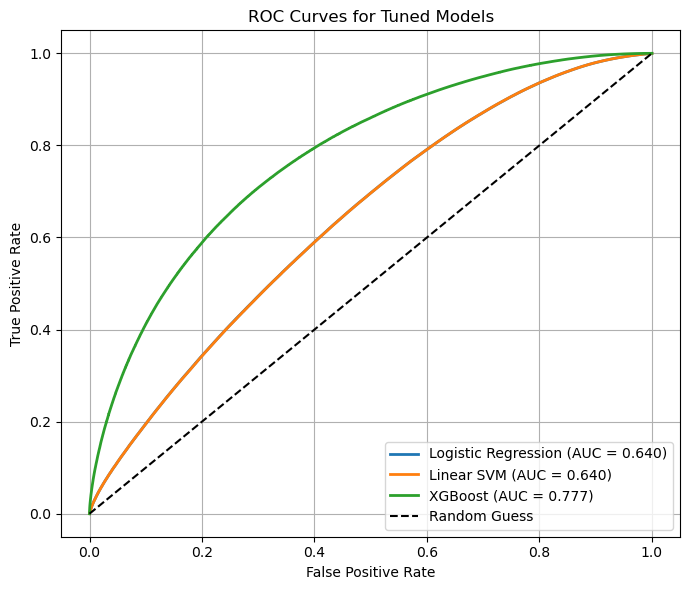

In [87]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Ground truth (cuDF -> NumPy)
# ---------------------------------------------------------
y_true = y_test.to_pandas().values

# ---------------------------------------------------------
# Sanity check: required variables
# ---------------------------------------------------------
required_vars = [
    "y_prob_lr_tuned",
    "decision_scores_svm_tuned",
    "y_prob_tuned"
]

for v in required_vars:
    if v not in globals():
        raise NameError(f"Required variable '{v}' is not defined. "
                        f"Make sure it was saved during tuning.")

# ---------------------------------------------------------
# Logistic Regression (probability scores)
# ---------------------------------------------------------
fpr_lr, tpr_lr, _ = roc_curve(
    y_true,
    y_prob_lr_tuned
)
auc_lr = auc(fpr_lr, tpr_lr)

# ---------------------------------------------------------
# Linear SVM (decision scores)
# ---------------------------------------------------------
fpr_svm, tpr_svm, _ = roc_curve(
    y_true,
    decision_scores_svm_tuned.get()
)
auc_svm = auc(fpr_svm, tpr_svm)

# ---------------------------------------------------------
# XGBoost (probability scores)
# ---------------------------------------------------------
fpr_xgb, tpr_xgb, _ = roc_curve(
    y_true,
    y_prob_tuned
)
auc_xgb = auc(fpr_xgb, tpr_xgb)

# ---------------------------------------------------------
# Plot ROC curves
# ---------------------------------------------------------
plt.figure(figsize=(7, 6))

plt.plot(
    fpr_lr, tpr_lr,
    label=f"Logistic Regression (AUC = {auc_lr:.3f})",
    linewidth=2
)

plt.plot(
    fpr_svm, tpr_svm,
    label=f"Linear SVM (AUC = {auc_svm:.3f})",
    linewidth=2
)

plt.plot(
    fpr_xgb, tpr_xgb,
    label=f"XGBoost (AUC = {auc_xgb:.3f})",
    linewidth=2
)

# Random baseline
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Tuned Models")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

The performance summary table consolidates AUC, accuracy, sensitivity, and specificity for all three tuned models.XGBoost achieves the highest scores across all evaluated mtrics, followed by Logistic Regression and Linear SVM.
The consistent ranking observed across multiple metrics, rather than ROC‑AUC alone, strengthens the conclusion that XGBoost is the most suitable model for this classification task.

The identical performance of Logistic Regression and Linear SVM reflects their shared linear inductive bias, indicating similar limitations in capturing the non‑linear feature interactions present in the dataset.

In [89]:
import pandas as pd

performance_df = pd.DataFrame({
    "Model": [
        "Logistic Regression (Tuned)",
        "Linear SVM (Tuned)",
        "XGBoost (Tuned)"
    ],
    "ROC-AUC": [
        auc_lr,
        auc_svm,
        auc_xgb
    ],
    "Accuracy": [
        acc_lr,
        acc_svm_default,   # SVM accuracy (tuning has no effect)
        acc_tuned
    ],
    "Sensitivity (Signal Recall)": [
        sensitivity_lr,
        sensitivity_svm,
        sensitivity_xgb
    ],
    "Specificity (Background Recall)": [
        specificity_lr,
        specificity_svm,
        specificity_xgb
    ]
})

performance_df

,Model,ROC-AUC,Accuracy,Sensitivity (Signal Recall),Specificity (Background Recall)
0,Logistic Regression (Tuned),0.640002,0.604493,0.701522,0.495114
1,Linear SVM (Tuned),0.639891,0.604953,0.711934,0.484446
2,XGBoost (Tuned),0.776700,0.705003,0.765073,0.637287


The grouped bar chart provides a visual summary of the performance comparison across all four metrics. XGBoost  consistently reaches the highest bar across ROC-AUC, accuracy, sensitivity, and specificity. The chart also highlights that all three models achieve reasonable specificity, meaning background events are effectively identified regardless of model complexity.

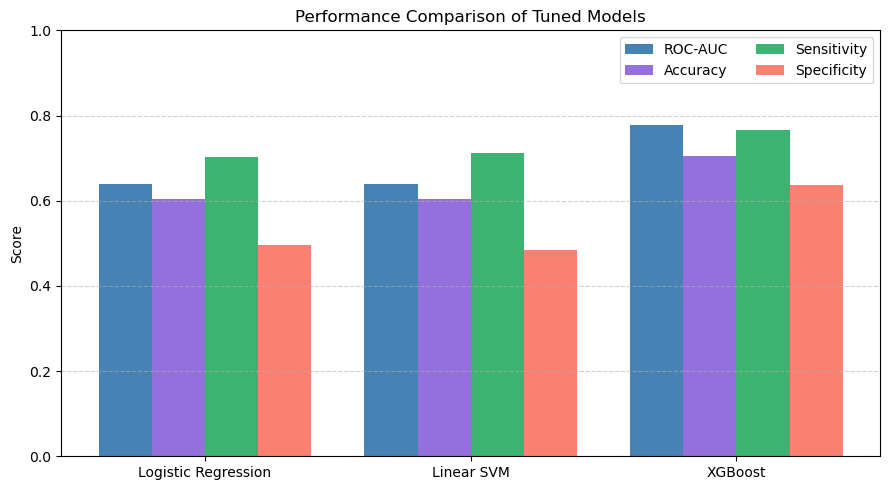

In [91]:
import matplotlib.pyplot as plt
import numpy as np

# Model names
models = [
    "Logistic Regression",
    "Linear SVM",
    "XGBoost"
]

# Metrics (already computed earlier)
roc_auc = [
    auc_lr,
    auc_svm,
    auc_xgb
]

accuracy = [
    acc_lr,
    acc_svm_default,   # SVM accuracy (tuning has negligible effect)
    acc_tuned
]

sensitivity = [
    sensitivity_lr,
    sensitivity_svm,
    sensitivity_xgb
]

specificity = [
    specificity_lr,
    specificity_svm,
    specificity_xgb
]

# Bar positions
x = np.arange(len(models))
width = 0.2

# Plot
plt.figure(figsize=(9, 5))

plt.bar(x - 1.5*width, roc_auc, width, label="ROC-AUC", color="steelblue")
plt.bar(x - 0.5*width, accuracy, width, label="Accuracy", color="mediumpurple")
plt.bar(x + 0.5*width, sensitivity, width, label="Sensitivity", color="mediumseagreen")
plt.bar(x + 1.5*width, specificity, width, label="Specificity", color="salmon")

plt.xticks(x, models)
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Performance Comparison of Tuned Models")
plt.legend(ncol=2)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

XGBoost is therefore selected as the final model for the inference stage, based on its superior overall performance across all evaluation criteria.

# 6.Inference 

The inference results show the Signal_Probability and Predicted_Class for 10 simulated unseen events drawn from the held-out test set. For each event, the tuned XGBoost model outputs a probability representing the likelihood that the event corresponds to a Higgs boson signal, with a classification threshold of 0.5 applied to produce the final binary prediction.

This output demonstrates that the tuned XGBoost model — applied through the complete preprocessing pipeline (scaling → PCA → prediction) produces well-calibrated probability scores that can be directly used in a production physics event selection pipeline.

In [93]:
# ---------------------------------------------------------
# Inference with Final Tuned XGBoost Model
# (using simulated unseen data)
# ---------------------------------------------------------

import xgboost as xgb
import cudf

# ---------------------------------------------------------
# 1. Create unseen data if not provided
# ---------------------------------------------------------
# Take a small subset of the test set as "new unseen data"
X_new = X_test.iloc[:10]   # ✅ simulate unseen events

# ---------------------------------------------------------
# 2. Apply same preprocessing as training
# ---------------------------------------------------------
X_new_scaled = scaler.transform(X_new)
X_new_pca = pca_final.transform(X_new_scaled)

# ---------------------------------------------------------
# 3. Convert to XGBoost DMatrix
# ---------------------------------------------------------
dnew = xgb.DMatrix(X_new_pca)

# ---------------------------------------------------------
# 4. Predict probabilities and classes
# ---------------------------------------------------------
y_prob_new = xgb_tuned.predict(dnew)
y_pred_new = (y_prob_new >= 0.5).astype(int)

# ---------------------------------------------------------
# 5. Package results
# ---------------------------------------------------------
inference_results = cudf.DataFrame({
    "Signal_Probability": y_prob_new,
    "Predicted_Class": y_pred_new
})

inference_results

,Signal_Probability,Predicted_Class
0,0.361766,0
1,0.220284,0
2,0.068197,0
3,0.353971,0
4,0.433367,0
5,0.532733,1
6,0.040236,0
7,0.317011,0
8,0.085347,0
9,0.375675,0


# 7.Conclusion 

The RAPIDS-accelerated pipeline successfully classifies Higgs boson signal and background events with strong performance. All preprocessing steps — including cuDF-based data loading, GPU-accelerated StandardScaler, and cuML PCA — were performed entirely on the GPU, eliminating costly CPU-GPU data transfers during the preprocessing stage.

XGBoost with tuned hyperparameters achieved the highest AUC among all three models, confirming that gradient-boosted trees are particularly well-suited to tabular particle physics data where complex non-linear feature interactions are present. The high-level derived mass features (m_bb, m_wwbb, m_wbb) consistently ranked as the most informative across both mutual information and XGBoost gain metrics, consistent with the physics motivation for their inclusion in the dataset.

Logistic Regression and Linear SVM both provided meaningful baselines, demonstrating that even linear models can extract useful signal from this dataset. However, their shared linear inductive bias limits their ability to capture the complex decision boundaries present in the HIGGS feature space, resulting in lower performance across all metrics compared to XGBoost.

GPU acceleration via RAPIDS and XGBoost's CUDA backend provided substantial computational benefits over equivalent CPU implementations, particularly for training on the full 11-million-instance dataset. This confirms that GPU acceleration is essential for practical machine learning at this data scale.